# Generating images of British and Irish butterfly specimens with a deep convolutional GAN

**Patrick Gilliland**, AI Mastery Capstone: Generative AI Applications

This notebook trains a generative adversarial network (GAN) to make new 64 by 64 colour images of butterfly specimens, as the Natural History Museum (NHM) photographs them in its iCollections unit trays. `generative_model.ipynb` and `generative_ai.ipynb` are the same notebook under the two names the brief uses. The report ships as `Generative_AI_Analysis_Report.pdf` and, with the same content, as `module_summary.pdf`. The works cited here are listed in the report's References.

**Run notes.** The notebook trains on a graphics processing unit (GPU) when one is visible, and otherwise on the central processing unit (CPU).

| Item | This notebook |
|---|---|
| Rig | NVIDIA GeForce RTX 5090 graphics card, Intel Core Ultra 9 285K processor, Linux under Windows Subsystem for Linux (WSL2) |
| Python | 3.12.3 |
| PyTorch | 2.14.1 from the Python Package Index (PyPI) |
| CUDA | 13.0 (the runtime PyTorch ships with), cuDNN 9.24.0 |

The measured GPU training time and the estimated CPU training time, both from the last full run, are in Task 4's run-summary table.

## Task 1: Define the Generative Task and Select Your Approach

**Goal.** I train a generative model that makes new 64 by 64 colour images of British and Irish butterfly specimens, pinned and photographed as the Museum photographs them. The content it produces is images, generated from random noise. There is no prompt and no class label: the generator turns a vector of 100 random numbers into one image.

**Approach.** From the brief's list, "Generative Adversarial Network (GAN) for image generation". The model is an unconditional deep convolutional GAN (DCGAN) at 64 by 64 pixels, written and trained in this notebook with no pre-trained network. Task 3 explains each design choice.

**Data.**
- **Publisher.** The Natural History Museum, London, on its Data Portal (https://data.nhm.ac.uk), Specimens resource `05ff2255-c38a-40c9-b657-4ccb55ab2feb`.
- **Selection.** The iCollections British and Irish butterflies (Paterson et al., 2016): order Lepidoptera, project iCollections, the six butterfly families one query at a time, each record with one specimen photograph under Creative Commons Attribution 4.0 (CC BY 4.0). Records with more than one specimen photograph were left out, and Task 2's anomaly table counts them.
- **Licence.** CC BY 4.0, checked on each image's own licence field. I credit the Museum in the form it asks for. Its terms say it cannot warrant the data, and nothing here suggests that it endorses this work.
- **Size and download.** 22,000 photographs, one per specimen, downloaded on 13 October 2026 in a seed-2026 random order by `scripts/download_nhm_images.py`. That script runs once, outside this notebook. The fixed manifest, `data/manifest_fixed_20261013.csv`, lists every photograph with its SHA-256 hash, and the cell after the environment check prints the manifest's own hash.
- **How it is used.** `scripts/build_working_set.py` crops each photograph to the specimen, leaving out the ruler and the labels, and resizes it to 64 by 64. A seeded 10 per cent of the specimens is held out for evaluation only. Crops that the rule's own failure flag marks are left out of training and of the held-out images (Task 2).

**The brief's dataset rules.**

| Rule (brief) | How this dataset meets it |
|---|---|
| Be appropriate for the chosen generative task | Thousands of photographs of one kind of object, taken to one protocol (Paterson et al., 2016, p. 4), which suits an image GAN |
| Be publicly available or clearly documented | Public on the NHM Data Portal under CC BY 4.0. The manifest and the download script document every photograph |
| Be appropriate for academic use | CC BY 4.0 allows reuse with attribution. The crop removes the labels, which carry collectors' handwriting and names, and the manifest keeps no field that names a person |
| Not be synthetic or AI-generated as a dataset | Photographs of real museum specimens |
| Not be reused from any previous capstone project | No earlier capstone project of mine used it. The prior-use search made before the dataset was chosen found none |

**How this could be used in the real world.** Three uses, strongest first. Each is my proposal, not something this notebook shows working.
1. **A quality flag for museum digitisation.** Museums photograph specimens in bulk and check the images afterwards. A European report on digitisation describes "the quality control activities that are performed after digitisation" (Nieva de la Hidalga et al., 2019, p. 4). The Museum and the Royal Botanic Garden Edinburgh describe a tool for "detecting missing objects (such as colour reference cards or barcodes), identifying cropping errors" on herbarium sheets (Zhang et al., 2026). In factory inspection, models learn from defect-free images alone, because "only a very limited amount of images with defects is available" (Bergmann et al., 2019, p. 2). My proposal: the trained discriminator has learned what a normal specimen photograph looks like, so it could score new photographs and pass the oddest to a person. Task 4 tests this once, on held-out photographs and known oddities.
2. **Images of rare species for identification tools.** Species photographs are uneven: "the natural world is heavily imbalanced, as some species are more abundant and easier to photograph than others" (Van Horn et al., 2018, p. 1). A GAN can be conditioned on a class label (Odena et al., 2017, p. 1). My proposal, as a next step: a conditional version of this GAN could add images of rare species to a training set. This notebook's GAN is unconditional and cannot choose a species.
3. **Material for spotting forged specimens.** The butterfly trade is regulated, and a guide for border officers notes that "Commercial shipments routinely use false declarations on import" (Environment Canada, 2000, p. 28). My proposal: generated fakes could help train people or tools to tell a real specimen photograph from a made one. No source I hold shows this done.

**Setup.** The first code cell sets two environment variables before PyTorch loads, seeds every random number generator and prints each seed. It fixes the settings that make a rerun repeat its numbers. When a GPU is visible, it prints the device, caps PyTorch at half the card's memory and prints how much of the 5090's memory is in use. That reading is for the record and never stops the notebook.

The cell also defines the training watchdog that Task 3 uses. It stops a run on a loss that is not a number, on an epoch over three times the median epoch before it, or on more than 20,000 MiB in use on the 5090. On this rig it also stops a run past 30 minutes. On any other machine that line only prints a warning, so a slower card still runs the notebook to the end.

In [1]:
import math
import os
import platform
import random
import statistics
import subprocess
import sys
import time
from pathlib import Path

# I pin the RTX 5090 (device 0) whatever the shell sets, because the rig's
# shell can show both its cards. The empty string is left alone: it hides
# every GPU for a CPU run. Deterministic cuBLAS needs its workspace set
# before torch loads.
if os.environ.get("CUDA_VISIBLE_DEVICES") != "":
    os.environ["CUDA_VISIBLE_DEVICES"] = "0"
os.environ.setdefault("CUBLAS_WORKSPACE_CONFIG", ":4096:8")

import numpy as np  # noqa: E402
import torch  # noqa: E402

SEED_DATA = 2026  # the download order, the held-out split, the crop's 400
SEED_TRAIN = 42  # training, the fixed noise and 64 training images
SEED_SAMPLES = 7  # the 64 numbered samples and the held-out grid
random.seed(SEED_TRAIN)
np.random.seed(SEED_TRAIN)
torch.manual_seed(SEED_TRAIN)
torch.cuda.manual_seed_all(SEED_TRAIN)

# Deterministic cuDNN kernels, no autotuning and no TF32, so a rerun gives
# the same numbers and the arithmetic stays float32.
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False
torch.backends.cuda.matmul.allow_tf32 = False
torch.backends.cudnn.allow_tf32 = False

GPU_NAME = "5090"
MEMORY_LINE_MIB = 20000
BUDGET_SECONDS = 1800.0


def smi_used_mib(text, name=GPU_NAME):
    """The memory in use, in MiB, on the first nvidia-smi row naming name.

    text is nvidia-smi's CSV output, with or without an index column and
    units. Returns None when no row names the card."""
    for line in text.splitlines():
        fields = [f.strip() for f in line.split(",")]
        for k, field in enumerate(fields[:-1]):
            if name in field:
                return int(fields[k + 1].split()[0])
    return None


def used_mib():
    """The 5090's memory in use, in MiB, or None with no GPU visible.

    Under WSL, torch.cuda.mem_get_info leaves out the Windows apps' share,
    so the reading is the larger of it and the card's nvidia-smi row, or
    mem_get_info alone where nvidia-smi is missing or has no 5090 row."""
    if not torch.cuda.is_available():
        return None
    free, total = torch.cuda.mem_get_info()
    readings = [(total - free) // 2**20]
    try:
        smi = subprocess.run(
            ["nvidia-smi", "--query-gpu=name,memory.used",
             "--format=csv,noheader,nounits"],
            capture_output=True, text=True, timeout=10, check=False,
        ).stdout
    except (OSError, subprocess.TimeoutExpired):
        smi = ""
    row = smi_used_mib(smi)
    if row is not None:
        readings.append(row)
    return max(readings)


def watchdog(loss, epoch_seconds, elapsed_seconds, used, on_rig,
             factor=3.0, budget_seconds=BUDGET_SECONDS,
             line_mib=MEMORY_LINE_MIB):
    """Why a training run should stop, and any warning, as (stop, warning).

    Either is None when it does not apply. A loss that is not finite stops
    a run anywhere. So does an epoch slower than factor times the median of
    the epochs before it, or used MiB above line_mib. A run past
    budget_seconds stops on the rig and only warns elsewhere, so a slower
    card still runs the notebook to the end. Every line is strict."""
    if not math.isfinite(loss):
        return f"the loss is {loss}", None
    if used is not None and used > line_mib:
        return f"the 5090 has {used} MiB in use, over {line_mib} MiB", None
    if len(epoch_seconds) > 1:
        line = factor * statistics.median(epoch_seconds[:-1])
        if epoch_seconds[-1] > line:
            return (
                f"the epoch took {epoch_seconds[-1]:.1f} s, over {line:.1f} s",
                None,
            )
    if elapsed_seconds > budget_seconds:
        minutes = f"{budget_seconds / 60:g} minutes"
        if on_rig:
            return f"the run passed {minutes}", None
        return None, f"the run passed {minutes}, so I carry on off the rig"
    return None, None


print(
    f"Python {platform.python_version()}, PyTorch {torch.__version__}, "
    f"NumPy {np.__version__}"
)
print(
    f"Seeds: data {SEED_DATA}, training {SEED_TRAIN}, samples {SEED_SAMPLES}"
)
print(
    f"CUDA_VISIBLE_DEVICES={os.environ['CUDA_VISIBLE_DEVICES']!r}, "
    f"CUBLAS_WORKSPACE_CONFIG={os.environ['CUBLAS_WORKSPACE_CONFIG']!r}"
)
on_gpu = torch.cuda.is_available()
if on_gpu:
    name = torch.cuda.get_device_name(0)
    on_rig = GPU_NAME in name
    cudnn = torch.backends.cudnn.version()
    print(
        f"Device: cuda, {name}, CUDA {torch.version.cuda}, "
        f"cuDNN {cudnn // 10000}.{cudnn % 10000 // 100}.{cudnn % 100}"
    )
    if not on_rig:
        print(f"Warning: not the RTX {GPU_NAME}, so the time line only warns")
    # Half the card at most, by this rig's GPU rules.
    torch.cuda.set_per_process_memory_fraction(0.5)
    print(f"GPU memory cap: half the card. In use on it now: {used_mib()} MiB")
else:
    on_rig = False
    print("Device: cpu, no GPU visible, so the time line only warns")

Python 3.12.3, PyTorch 2.14.1+cu130, NumPy 2.5.4
Seeds: data 2026, training 42, samples 7
CUDA_VISIBLE_DEVICES='0', CUBLAS_WORKSPACE_CONFIG=':4096:8'
Device: cuda, NVIDIA GeForce RTX 5090, CUDA 13.0, cuDNN 9.24.0


GPU memory cap: half the card. In use on it now: 5242 MiB


**Environment check.** The brief's own validation code, as given, reading this project's data file, the fixed manifest. In one cell only the last line's value is shown, so `device` on its own line prints nothing here. The setup cell above prints the device.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch

device = "cuda" if torch.cuda.is_available() else "cpu"
device
df = pd.read_csv("data/manifest_fixed_20261013.csv")
df.head()

,occurrence_id,catalog_number,family,genus,species,country,image_url,rendition,download_url,licence,file_name,sha256,bytes,width,height,download_utc
0,d3a4acf9-13dc-42bf-b13a-85e20cd62514,BMNH(E)1038104,Nymphalidae,Aphantopus,hyperantus,United Kingdom,https://data.nhm.ac.uk/media/b9470c19-d4cf-439...,original,https://data.nhm.ac.uk/media/b9470c19-d4cf-439...,http://creativecommons.org/licenses/by/4.0/,BMNH-E-1038104_d3a4acf913dc42bfb13a85e20cd6251...,7cb05980550f9c5c321265dbcd93b33292f73df686da37...,139014,1440,960,2026-10-13T17:40:00Z
1,1403dc68-1fbf-4f26-964f-e0ece3da28b9,BMNH(E)1038105,Nymphalidae,Aphantopus,hyperantus,United Kingdom,https://data.nhm.ac.uk/media/06491a4b-f253-44c...,original,https://data.nhm.ac.uk/media/06491a4b-f253-44c...,http://creativecommons.org/licenses/by/4.0/,BMNH-E-1038105_1403dc681fbf4f26964fe0ece3da28b...,327b36c56a9e9244638e02aa1029d48935e3a400f304e3...,148736,1440,960,2026-10-13T18:40:30Z
2,33dd91df-c8a1-4d83-99bc-a47f4b48c157,BMNH(E)1038110,Nymphalidae,Aphantopus,hyperantus,United Kingdom,https://data.nhm.ac.uk/media/420495a5-3c7b-46a...,original,https://data.nhm.ac.uk/media/420495a5-3c7b-46a...,http://creativecommons.org/licenses/by/4.0/,BMNH-E-1038110_33dd91dfc8a14d8399bca47f4b48c15...,43b8685b9896fe9ff1dc43a2f5c6b9629cfb0a369dd3d0...,159091,1440,960,2026-10-13T16:43:35Z
3,2f9f0e9a-ba00-4988-a633-87453f980509,BMNH(E)1038115,Nymphalidae,Aphantopus,hyperantus,United Kingdom,https://data.nhm.ac.uk/media/897860cb-5b64-475...,original,https://data.nhm.ac.uk/media/897860cb-5b64-475...,http://creativecommons.org/licenses/by/4.0/,BMNH-E-1038115_2f9f0e9aba004988a63387453f98050...,210337dad473e3fa75ed043e7dfdddccf88067291115c2...,310657,1440,2160,2026-10-13T17:44:18Z
4,0d630cab-f8b2-4df3-a3fc-adad35685fd5,BMNH(E)1038140,Nymphalidae,Aphantopus,hyperantus,Ireland,https://data.nhm.ac.uk/media/32e4f459-6944-405...,original,https://data.nhm.ac.uk/media/32e4f459-6944-405...,http://creativecommons.org/licenses/by/4.0/,BMNH-E-1038140_0d630cabf8b24df3a3fcadad35685fd...,7cc16172ebfde0cde3b14506822fae181abf0c14d04415...,284676,1440,2160,2026-10-13T15:53:44Z


**The fixed set.** The next cell loads the crop rule and the split from the repository's `scripts/build_working_set.py`, then checks the manifest against the hash it was frozen with and prints when the photographs were downloaded.

In [3]:
# The crop rule, the flag and the split live in the repository's scripts
# folder, so the notebook and the array builder share one copy.
sys.path.insert(0, str(Path("scripts").resolve()))
import build_working_set as bws  # noqa: E402

MANIFEST = Path("data/manifest_fixed_20261013.csv")
MANIFEST_SHA256 = (
    "920fd9330771a12403a8cd07dea9b145dad633b7a86de81847b8a6c237cbbc80"
)
manifest = pd.read_csv(MANIFEST, keep_default_na=False)
digest = bws.file_sha256(MANIFEST)
print(f"Fixed manifest: {MANIFEST}, {len(manifest):,} photographs")
print(f"SHA-256 {digest}, the frozen hash: {digest == MANIFEST_SHA256}")
print(
    f"Downloaded from {manifest['download_utc'].min()} to "
    f"{manifest['download_utc'].max()} (UTC), in a seed-{SEED_DATA} order"
)
print(
    f"Held out for evaluation: {bws.HELD_OUT_FRACTION * 100:.0f} per cent "
    f"of the specimens, seed {bws.SEED}"
)

Fixed manifest: data/manifest_fixed_20261013.csv, 22,000 photographs
SHA-256 920fd9330771a12403a8cd07dea9b145dad633b7a86de81847b8a6c237cbbc80, the frozen hash: True
Downloaded from 2026-10-13T14:59:57Z to 2026-10-13T19:00:32Z (UTC), in a seed-2026 order
Held out for evaluation: 10 per cent of the specimens, seed 2026


## Task 2: Load and Inspect Your Data or Prompt Source

**Goal.** Load the fixed manifest and the 64 by 64 working arrays, then show real photographs and their crops, and inspect the data's structure, formats and sizes before any model sees it. Every cell here reads only `data/`: the manifest, the photographs in `data/raw/`, and the arrays and row table that `scripts/build_working_set.py split` writes.

In [4]:
from IPython.display import display  # noqa: E402

STEM = "data/nhm_butterflies_64"
PARTS = ("training", "held_out", "flagged")
array_paths = {part: Path(f"{STEM}_{part}.npy") for part in PARTS}
rows_path = Path(f"{STEM}_rows.csv")
if not all(p.exists() for p in [*array_paths.values(), rows_path]):
    # Rebuilding crops and flags all 22,000 photographs: about three minutes
    # on this rig with 12 worker processes.
    started = time.perf_counter()
    status = bws.main([
        "split", "--manifest", str(MANIFEST), "--raw-dir", "data/raw",
        "--out", STEM, "--workers", "8",
    ])
    if status != 0:
        raise RuntimeError("the working arrays could not be built")
    print(f"Rebuilt the arrays in {time.perf_counter() - started:.0f} s")
arrays = {part: np.load(path) for part, path in array_paths.items()}
rows = pd.read_csv(rows_path, keep_default_na=False)
if list(rows["file_name"]) != list(manifest["file_name"]):
    raise ValueError("the row table is not in the manifest's order")
for part, path in array_paths.items():
    print(f"{path}: SHA-256 {bws.file_sha256(path)}")
print(f"{rows_path}: {len(rows):,} rows, one per manifest row")

data/nhm_butterflies_64_training.npy: SHA-256 4b697a5536b0329ac4b9972fa6bdfebfe898fdc5263bef3380734ab6f43bc131
data/nhm_butterflies_64_held_out.npy: SHA-256 dfbdb68e728444c3da975b2944df760e847d6c11ee2f087f2bd20700791ff568


data/nhm_butterflies_64_flagged.npy: SHA-256 b9ba67c14c869ef788dee3e334ae717a59d13c2c1d59574d53b3afde6e09315d
data/nhm_butterflies_64_rows.csv: 22,000 rows, one per manifest row


**The manifest.** One row per photograph: the specimen's identifiers and names, where it was collected, both download addresses, the licence, the file's name, hash, size in bytes and pixel size, and when it was downloaded. Nothing in it names a person. The tables count the photographs by family and by country.

In [5]:
def count_table(values, name):
    """Counts and per cent shares of values, largest first, as a new frame.

    A blank value is shown as "(blank)", so a missing country is counted
    and not dropped."""
    counts = values.replace("", "(blank)").value_counts()
    return pd.DataFrame({
        name: counts.index,
        "images": counts.to_numpy(),
        "per cent": (100 * counts.to_numpy() / counts.sum()).round(1),
    })


CC_BY = "http://creativecommons.org/licenses/by/4.0/"
print(f"Shape: {manifest.shape[0]:,} rows by {manifest.shape[1]} columns")
print(manifest.dtypes.to_string())
licensed = int((manifest["licence"] == CC_BY).sum())
print(f"Rows whose own licence field is CC BY 4.0: {licensed:,}")
print("Photographs by source rendition and pixel size:")
print(manifest.groupby(["rendition", "width", "height"]).size().to_string())
print(f"512-pixel renditions: {(manifest['rendition'] != 'original').sum()}")
display(count_table(manifest["family"], "family"))
display(count_table(manifest["country"], "country"))

Shape: 22,000 rows by 16 columns
occurrence_id       str
catalog_number      str
family              str
genus               str
species             str
country             str
image_url           str
rendition           str
download_url        str
licence             str
file_name           str
sha256              str
bytes             int64
width             int64
height            int64
download_utc        str
Rows whose own licence field is CC BY 4.0: 22,000
Photographs by source rendition and pixel size:
rendition                    width  height
full/!512,512/0/default.jpg  341    512         136
                             512    341          29
original                     1440   960        7292
                                    2160      14543
512-pixel renditions: 165


,family,images,per cent
0,Lycaenidae,9397,42.7
1,Nymphalidae,8520,38.7
2,Pieridae,2713,12.3
3,Hesperiidae,1056,4.8
4,Riodinidae,213,1.0
5,Papilionidae,101,0.5


,country,images,per cent
0,United Kingdom,18944,86.1
1,(blank),2064,9.4
2,Ireland,968,4.4
3,Isle of Man,24,0.1


**What the tables show.** Every row carries the CC BY 4.0 licence on its own image. Two families, Lycaenidae (the blues, coppers and hairstreaks) and Nymphalidae, make up most of the set, and Papilionidae, the swallowtails, are the fewest. Most photographs come from the United Kingdom, with Ireland and the Isle of Man after it, and some have no country, so I never call the set "UK only". Most photographs are 1,440 pixels wide, portrait or landscape, and a few are the Museum's 512-pixel rendition. The crop works in proportions of the photograph, so both sizes crop alike.

**Real photographs (Figure 1).** Six training photographs, drawn with seed 42 from those whose crop the flag passed. Each is shown whole, with the ruler, and with the label section beyond the crop painted grey, because the labels carry collectors' handwriting and names. I mask both the side where the rule found the labels and the side where a tray of that shape keeps them, in case the rule read the side wrongly. Their attribution lines follow, in the Museum's form; the manifest holds no update year, so it is given as n.d.

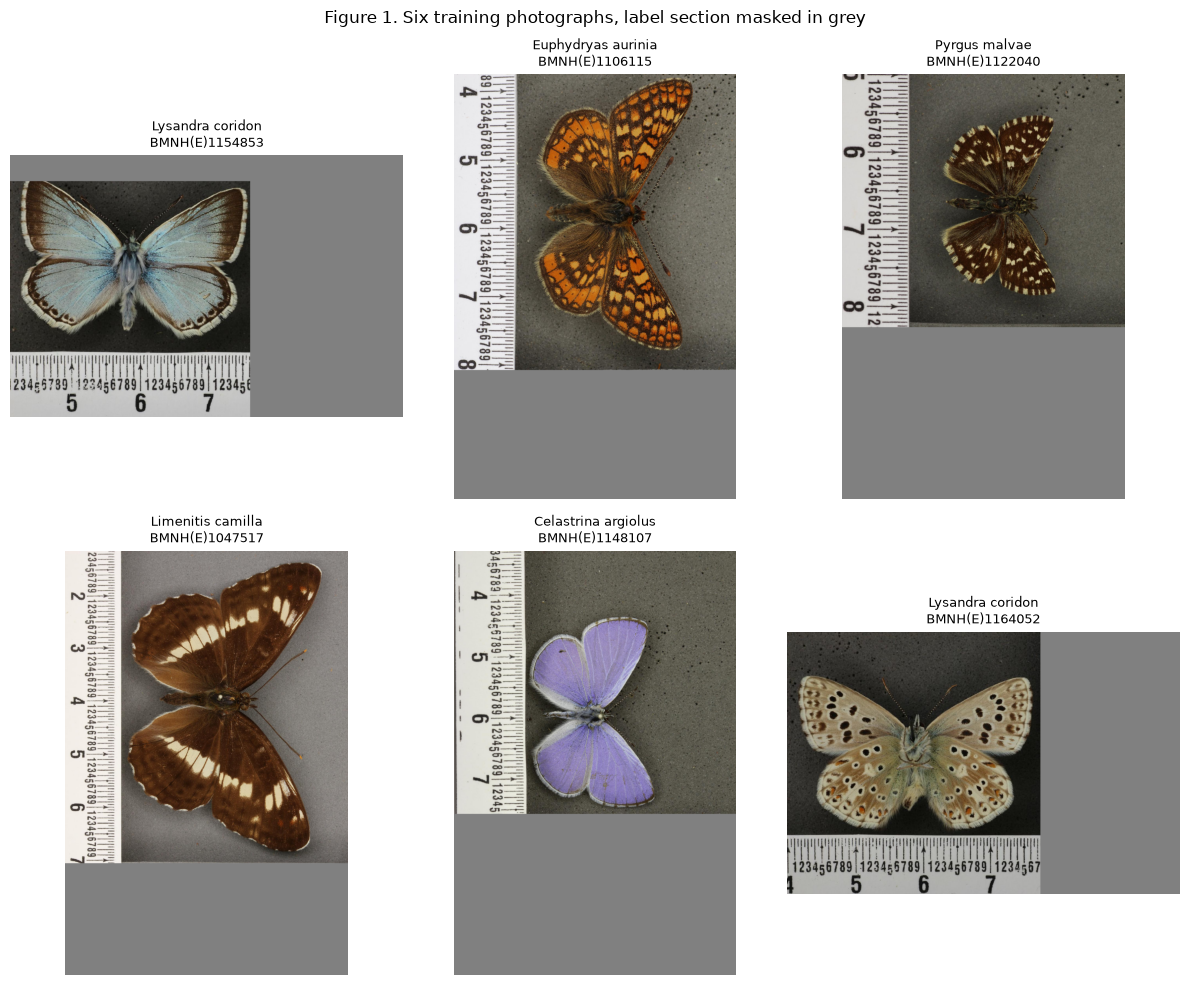

Natural History Museum. (n.d.). Lysandra coridon, BMNH(E)1154853 (from Collection specimens) [Photograph]. Natural History Museum. Licensed under CC-BY-4.0 (https://creativecommons.org/licenses/by/4.0). https://data.nhm.ac.uk/object/caa64824-9f1f-4278-836f-ad1fc943e857
Natural History Museum. (n.d.). Euphydryas aurinia, BMNH(E)1106115 (from Collection specimens) [Photograph]. Natural History Museum. Licensed under CC-BY-4.0 (https://creativecommons.org/licenses/by/4.0). https://data.nhm.ac.uk/object/20cef50d-fba5-466e-987f-002ce6b0b81c
Natural History Museum. (n.d.). Pyrgus malvae, BMNH(E)1122040 (from Collection specimens) [Photograph]. Natural History Museum. Licensed under CC-BY-4.0 (https://creativecommons.org/licenses/by/4.0). https://data.nhm.ac.uk/object/6e2e53fd-5bec-4bcb-a6c8-fea20957001c
Natural History Museum. (n.d.). Limenitis camilla, BMNH(E)1047517 (from Collection specimens) [Photograph]. Natural History Museum. Licensed under CC-BY-4.0 (https://creativecommons.org/licen

In [6]:
def mask_label_side(rgb, box, side, grey=128):
    """A copy of rgb with everything past box on the label side made grey.

    box is (left, top, right, bottom) pixels and side is the label side the
    crop rule found, or None, when nothing is painted."""
    out = rgb.copy()
    left, top, right, bottom = box
    if side == "bottom":
        out[bottom:] = grey
    elif side == "top":
        out[:top] = grey
    elif side == "right":
        out[:, right:] = grey
    elif side == "left":
        out[:, :left] = grey
    return out


def label_sides(shape, side):
    """The sides to mask past the crop, as a list: the side the rule read,
    and the orientation's own label side, the bottom of a portrait tray or
    the right of a landscape one, in case the rule read it wrongly."""
    usual = "bottom" if shape[0] > shape[1] else "right"
    return [side, usual] if side not in (None, usual) else [usual]


def masked(photo, parts):
    """A copy of photo with every label side past the crop made grey."""
    out = photo
    for side in label_sides(photo.shape, parts["side"]):
        out = mask_label_side(out, parts["box"], side)
    return out


def attribution(row):
    """The Museum's attribution line for one manifest row, as a string.

    The title is the specimen's name and catalogue number, and the year is
    n.d., because the manifest keeps no update year."""
    name = " ".join(p for p in (row["genus"], row["species"]) if p)
    return (
        f"Natural History Museum. (n.d.). {name}, {row['catalog_number']} "
        "(from Collection specimens) [Photograph]. Natural History Museum. "
        "Licensed under CC-BY-4.0 "
        "(https://creativecommons.org/licenses/by/4.0). "
        f"https://data.nhm.ac.uk/object/{row['occurrence_id']}"
    )


passed = rows[(rows["part"] == "training") & (rows["flagged"] == 0)]
shown = passed.sample(6, random_state=SEED_TRAIN)["row"].to_list()
fig, axes = plt.subplots(2, 3, figsize=(12, 10))
for ax, k in zip(axes.flat, shown):
    record = manifest.iloc[k]
    photo = bws.load_photograph(Path("data/raw") / record["file_name"])
    parts = bws.segment_parts(photo)
    ax.imshow(masked(photo, parts))
    ax.set_title(
        f"{record['genus']} {record['species']}\n{record['catalog_number']}",
        fontsize=9,
    )
    ax.axis("off")
fig.suptitle(
    "Figure 1. Six training photographs, label section masked in grey"
)
plt.tight_layout()
plt.show()
for k in shown:
    print(attribution(manifest.iloc[k]))

**The crop rule and its failure flag (Figure 2).** The rule finds the ruler and the labels, marks what differs from the tray's grey, and boxes the specimen with a small margin. Each crop is padded to a square with the tray's colour and resized to 64 by 64 with Pillow's bilinear filter. Figure 2 shows the box in red on four more training photographs, their 64 by 64 crops, and 16 crops the flag marked.

Before any training I counted crop failures by eye on contact sheets: a failure is a crop where a wing, the body or a label crosses the box edge. The rule's own signals then give an automatic flag, set once on the 200 development images. It flags a crop when no specimen was found, when the specimen is under 5 or over 60 per cent of the tray, when marks cross more than a third of a side of the box, or when white paper lies along more than 5 per cent of a side. The eye counts and the flag's agreement with them are printed below the figure, with the totals the flag marks in the fixed set.

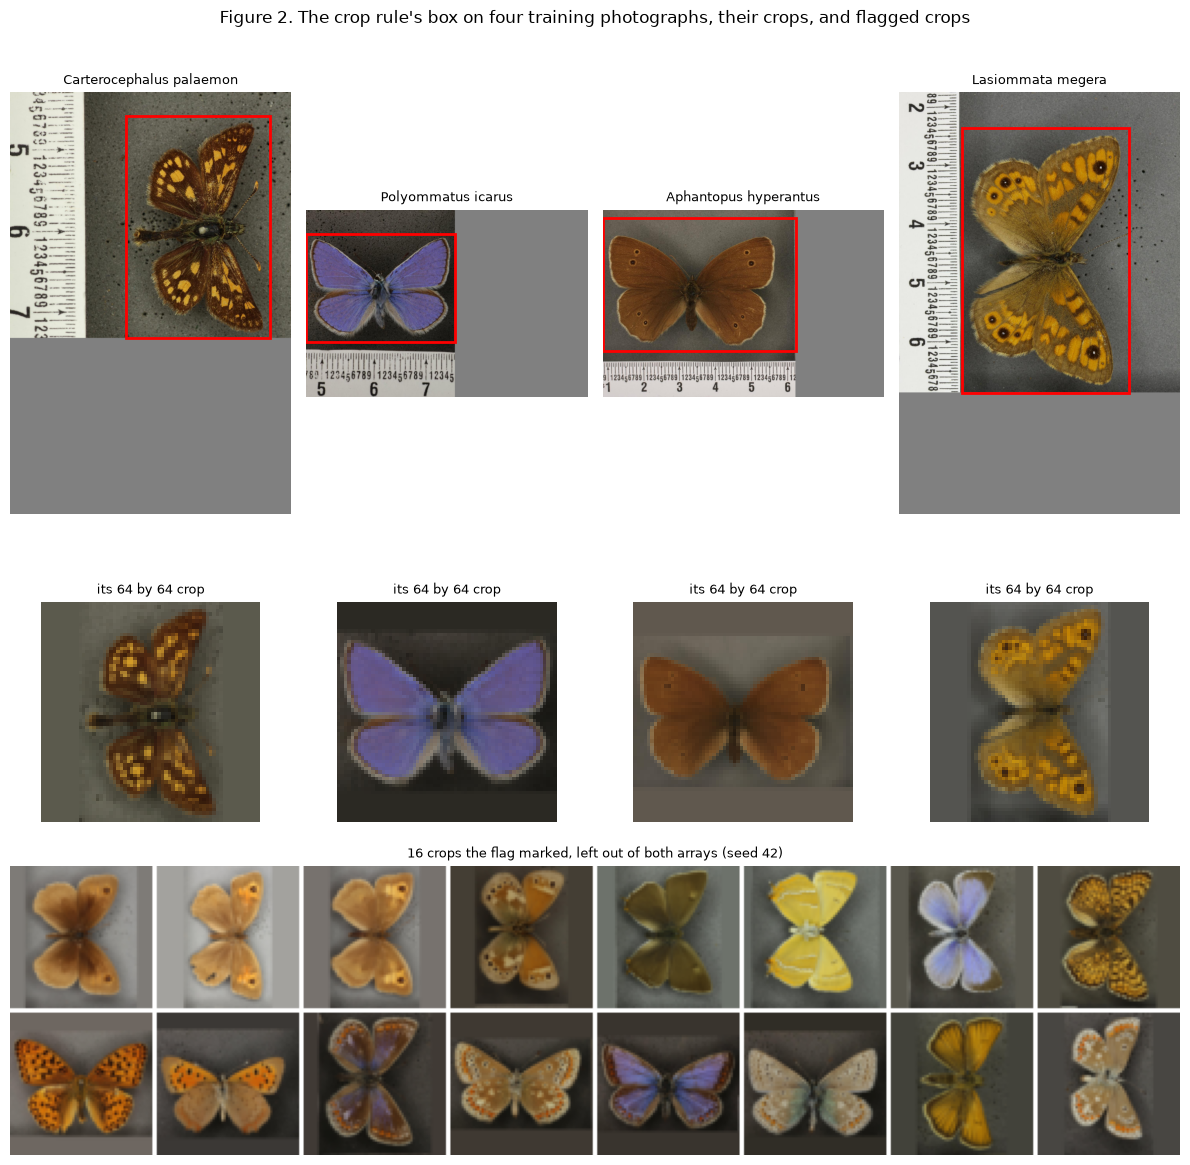

Development sample: 10 failures by eye of 200 (5.0 per cent). Flag: 9 caught, 29 false alarms, 1 missed, 161 cleared; precision 0.237, recall 0.900
Provisional sample: 24 failures by eye of 400 (6.0 per cent). Flag: 9 caught, 62 false alarms, 15 missed, 314 cleared; precision 0.127, recall 0.375
Flagged in the fixed set: 4,233 of 22,000 (19.2 per cent), by reason:
flag_reasons
edge crossed                                  3276
paper at edge                                  497
edge crossed; paper at edge                    419
specimen area                                   20
no specimen                                      8
specimen area; edge crossed                      6
no specimen; paper at edge                       6
specimen area; edge crossed; paper at edge       1


In [7]:
def tile(images, cols, pad=2, fill=255):
    """The images laid out in rows of cols, with pad pixels of fill between
    them, as a new uint8 array."""
    n, h, w, c = images.shape
    rows_needed = math.ceil(n / cols)
    out = np.full(
        (rows_needed * h + (rows_needed - 1) * pad,
         cols * w + (cols - 1) * pad, c),
        fill, dtype=np.uint8,
    )
    for k in range(n):
        r, q = divmod(k, cols)
        y, x = r * (h + pad), q * (w + pad)
        out[y:y + h, x:x + w] = images[k]
    return out


others = passed[~passed["row"].isin(shown)]
crop_rows = others.sample(4, random_state=SEED_TRAIN)
flag_draw = np.random.default_rng(SEED_TRAIN).choice(
    len(arrays["flagged"]), 16, replace=False
)
fig = plt.figure(figsize=(12, 12))
grid = fig.add_gridspec(3, 4, height_ratios=[3.2, 1.3, 1.9])
for col, (_, r) in enumerate(crop_rows.iterrows()):
    record = manifest.iloc[r["row"]]
    photo = bws.load_photograph(Path("data/raw") / record["file_name"])
    parts = bws.segment_parts(photo)
    left, top, right, bottom = parts["box"]
    ax = fig.add_subplot(grid[0, col])
    ax.imshow(masked(photo, parts))
    ax.add_patch(plt.Rectangle((left, top), right - left, bottom - top,
                               fill=False, edgecolor="red", linewidth=2))
    ax.set_title(f"{record['genus']} {record['species']}", fontsize=9)
    ax.axis("off")
    ax = fig.add_subplot(grid[1, col])
    ax.imshow(arrays["training"][int(r["array_row"])])
    ax.set_title("its 64 by 64 crop", fontsize=9)
    ax.axis("off")
ax = fig.add_subplot(grid[2, :])
ax.imshow(tile(arrays["flagged"][np.sort(flag_draw)], cols=8))
ax.set_title("16 crops the flag marked, left out of both arrays (seed 42)",
             fontsize=9)
ax.axis("off")
fig.suptitle("Figure 2. The crop rule's box on four training photographs, "
             "their crops, and flagged crops")
plt.tight_layout()
plt.show()

# The eye count from the contact sheets, made before any training and kept
# outside this notebook, as (failures, images); then the flag against it as
# (caught, false alarms, missed, cleared), from the same sheets.
EYE_COUNT = {"development": (10, 200), "provisional": (24, 400)}
AGREEMENT = {"development": (9, 29, 1, 161), "provisional": (9, 62, 15, 314)}
for sample, (failed, seen) in EYE_COUNT.items():
    tp, fp, missed, tn = AGREEMENT[sample]
    print(
        f"{sample.capitalize()} sample: {failed} failures by eye of {seen} "
        f"({100 * failed / seen:.1f} per cent). Flag: {tp} caught, {fp} "
        f"false alarms, {missed} missed, {tn} cleared; precision "
        f"{tp / (tp + fp):.3f}, recall {tp / (tp + missed):.3f}"
    )
print(
    f"Flagged in the fixed set: {rows['flagged'].sum():,} of {len(rows):,} "
    f"({100 * rows['flagged'].mean():.1f} per cent), by reason:"
)
print(rows["flag_reasons"][rows["flagged"] == 1].value_counts().to_string())

**What the crop check shows.** By eye, the rule fails on about one crop in twenty. The flag catches most failures on the development images it was set on, but on the 400 provisional images it misses most of them and many of the crops it marks would pass by eye. So it is a cautious filter, not an exact one. It leaves out about one photograph in five, and some failed crops still reach training. Most marked crops have marks across an edge of the box: a wing that runs to the edge, the platform's edge, or the top of a label.

**The working arrays (Figure 3).** One uint8 array per part, with one 64 by 64 RGB image per photograph the flag passed, in manifest order. The cell prints each array's shape, type, size and pixel range, and Figure 3 shows 64 training images drawn with seed 42.

training: shape (16000, 64, 64, 3), dtype uint8, 187.5 MiB, pixel values 0 to 255
held_out: shape (1767, 64, 64, 3), dtype uint8, 20.7 MiB, pixel values 0 to 251


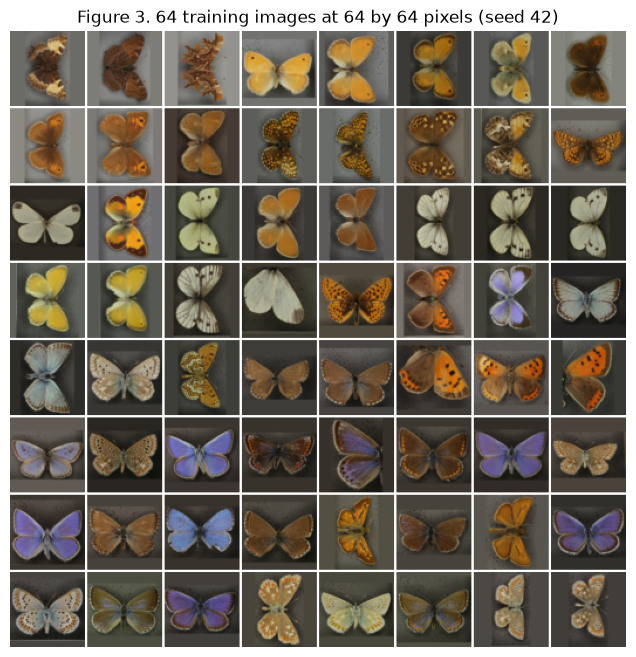

In [8]:
for part in ("training", "held_out"):
    a = arrays[part]
    print(
        f"{part}: shape {a.shape}, dtype {a.dtype}, "
        f"{a.nbytes / 2**20:.1f} MiB, pixel values {a.min()} to {a.max()}"
    )
train64 = np.sort(np.random.default_rng(SEED_TRAIN).choice(
    len(arrays["training"]), 64, replace=False
))
plt.figure(figsize=(8, 8))
plt.imshow(tile(arrays["training"][train64], cols=8))
plt.title("Figure 3. 64 training images at 64 by 64 pixels (seed 42)")
plt.axis("off")
plt.show()

**The held-out split.** A seeded 10 per cent of the specimens is held out: the first tenth of NumPy's `default_rng(2026)` permutation over the manifest's rows, which the manifest keeps sorted by file name. With one photograph per specimen, a split by photograph is a split by specimen. The cell prints each part's size with and without the flagged crops, then the families on each side and how often the flag marks each family and each rendition.

In [9]:
print(
    f"Seed {bws.SEED}: {bws.HELD_OUT_FRACTION * 100:.0f} per cent held out, "
    f"{bws.held_out_count(len(rows)):,} of {len(rows):,} specimens"
)
for part, label in (("training", "Training"), ("held_out", "Held out")):
    p = rows[rows["part"] == part]
    flagged = int(p["flagged"].sum())
    print(
        f"{label}: {len(p):,} photographs with the flagged crops, "
        f"{len(p) - flagged:,} without them ({flagged:,} flagged)"
    )
with_family = rows.assign(family=manifest["family"].to_numpy())
kept = with_family[with_family["flagged"] == 0]
families = pd.DataFrame({
    "training": with_family.loc[with_family["part"] == "training", "family"]
    .value_counts(),
    "training kept": kept.loc[kept["part"] == "training", "family"]
    .value_counts(),
    "held out": with_family.loc[with_family["part"] == "held_out", "family"]
    .value_counts(),
    "held out kept": kept.loc[kept["part"] == "held_out", "family"]
    .value_counts(),
}).fillna(0).astype(int).sort_values("training", ascending=False)
families["training per cent"] = (
    100 * families["training"] / families["training"].sum()
).round(1)
families["kept per cent"] = (
    100 * families["training kept"] / families["training kept"].sum()
).round(1)
families["flagged per cent"] = (
    100 * with_family.groupby("family")["flagged"].mean()
).round(1)
display(families)
by_rendition = (
    100 * rows.groupby(manifest["rendition"].to_numpy())["flagged"].mean()
).round(1)
print("Flagged per cent by rendition:")
print(by_rendition.to_string())

Seed 2026: 10 per cent held out, 2,200 of 22,000 specimens
Training: 19,800 photographs with the flagged crops, 16,000 without them (3,800 flagged)
Held out: 2,200 photographs with the flagged crops, 1,767 without them (433 flagged)


,training,training kept,held out,held out kept,training per cent,kept per cent,flagged per cent
family,,,,,,,
Lycaenidae,8453,6704,944,737,42.7,41.9,20.8
Nymphalidae,7672,6160,848,675,38.7,38.5,19.8
Pieridae,2459,2083,254,215,12.4,13.0,15.3
Hesperiidae,941,856,115,107,4.8,5.4,8.8
Riodinidae,181,142,32,29,0.9,0.9,19.7
Papilionidae,94,55,7,4,0.5,0.3,41.6


Flagged per cent by rendition:
full/!512,512/0/default.jpg    19.4
original                       19.2


**Preprocessing considerations.**
- **The crop is fixed.** It is set once, before training, and used for every run. It is a function of the photograph alone, with no learned part. Goodfellow et al. (2016, sec. 20.14, p. 714) warn that "changes in preprocessing, even very small and subtle ones, are completely unacceptable" when generative models are compared.
- **Square, then resize.** Each crop is padded to a square with the tray's own colour, so the specimen keeps its shape, then resized to 64 by 64 with Pillow's bilinear filter and stored as uint8.
- **Scaling for the generator.** Task 3 scales the pixels to the range -1 to 1, for the generator's Tanh output, on the GPU one batch at a time. Radford et al. (2016, sec. 4, p. 3) did the same: "No pre-processing was applied to training images besides scaling to the range of the tanh activation function [-1, 1]." Training adds one step of its own, a random horizontal flip of each image.
- **Two resolutions.** 165 photographs are the Museum's 512-pixel rendition. Every crop is shrunk far below that size, and the flag marks the renditions at about the same rate as the originals.
- **Flagged crops.** They are left out of both arrays and stay in the row table. The flag marks large specimens more often, so leaving them out shifts the family shares a little: the swallowtails are flagged most and the skippers least.
- **The held-out images.** They are read once, in Task 4, and never used to train the model or to choose a setting.

## Task 3: Implement and Train a Generative Model

## Task 4: Generate and Evaluate Outputs

## Task 5: Write a Short Notebook Summary